In [1]:
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt

from agfx.gym import create_state, from_amat, enumerate_ancestral_graphs
from agfx.special.linear_gaussian import sample_linear_gaussian
from agfx.rewards import create_log_reward, LogRewardType 
from agfx.training import train, LossType
from agfx.policies import GFlowNet
from agfx.evals import eval_marginal, eval_true_marginal

In [ ]:
num_nodes = 5
bs = 64

iterations = int(2e3)
logr_t = LogRewardType.BIC
loss_t = LossType.CB

seed = 42
dmid = 64
lrs = [1e-5, 1e-2, 1]

reward_seed = 43

In [22]:
all_graphs = enumerate_ancestral_graphs(num_nodes)

In [4]:
reward_key = jax.random.key(reward_seed)
# Simulate the data (which is needed for certain reward functions)
data, dir_amat, bidir_amat, *_ = sample_linear_gaussian(
    reward_key, num_nodes, num_samples=500
)
true_graph = from_amat((dir_amat + bidir_amat)[None])

In [23]:
# Create the reward function
logr = create_log_reward(logr_t, data, true_graph)
true_marginals = eval_true_marginal(logr, all_graphs)

In [25]:
true_marginals

Array([[6.91156096e-18, 4.88456339e-01, 2.24968456e-02, 4.88604665e-01],
       [9.96352673e-01, 1.87283661e-03, 1.84073768e-04, 1.14818127e-03],
       [9.94965851e-01, 1.63849886e-03, 1.32705376e-03, 1.62628607e-03],
       [9.57126558e-01, 1.13390405e-02, 1.22351497e-02, 1.88567676e-02],
       [0.00000000e+00, 9.88842249e-01, 5.71054127e-03, 5.00465557e-03],
       [0.00000000e+00, 1.50150768e-02, 6.25254571e-01, 3.59288126e-01],
       [9.90686655e-01, 2.58762809e-03, 2.89761089e-03, 3.38578015e-03],
       [9.87485230e-01, 2.84044683e-04, 9.07584373e-03, 2.71258550e-03],
       [9.95459378e-01, 8.98629834e-04, 2.16172356e-03, 1.03781826e-03],
       [6.15744590e-36, 4.88322198e-01, 3.09913427e-01, 2.01322153e-01]],      dtype=float32)

In [24]:
marginals_per_dmid = {} 

for lr in lrs:
    if dmid not in marginals_per_dmid:
        marginals_per_dmid[lr] = []

    key = jax.random.key(seed)
    state = create_state(bs, num_nodes)
    # Create the GFlowNet
    gfn = GFlowNet(num_nodes, dmid)

    gfn, _ = train(gfn, state, key, logr, iterations, loss_t, lr=lr)

    _, estimated_marginals = eval_marginal(
        gfn, state, logr, graphs=all_graphs, key=key, num_rollouts=20, should_eval_gt=False
    )

    marginals_per_dmid[lr] = estimated_marginals


100%|██████████| 2000/2000 [00:33<00:00, 60.23it/s, loss=4.77e+03]


true None
estimated [[0.29296875 0.26796874 0.21718751 0.221875  ]
 [0.24453126 0.15546875 0.16250001 0.4375    ]
 [0.4359375  0.13671875 0.14609376 0.28125   ]
 [0.26796874 0.22265625 0.30390626 0.20546876]
 [0.17109375 0.140625   0.32265624 0.365625  ]
 [0.3234375  0.2421875  0.20234375 0.23203126]
 [0.23125    0.1640625  0.3421875  0.26250002]
 [0.25       0.38984376 0.11796875 0.2421875 ]
 [0.28593752 0.3375     0.25390625 0.12265625]
 [0.18828125 0.17421876 0.45000002 0.1875    ]]


100%|██████████| 2000/2000 [00:32<00:00, 61.84it/s, loss=1.81e+01]


true None
estimated [[0.0000000e+00 6.8750001e-02 9.1328126e-01 1.7968750e-02]
 [9.2656249e-01 2.4218751e-02 8.5937502e-03 4.0625002e-02]
 [9.7734374e-01 1.5625000e-03 2.1093750e-02 0.0000000e+00]
 [9.4999999e-01 1.7187500e-02 1.7968750e-02 1.4843750e-02]
 [0.0000000e+00 7.8125001e-04 5.2187502e-01 4.7734377e-01]
 [0.0000000e+00 2.6406249e-01 6.9375002e-01 4.2187501e-02]
 [9.8046875e-01 2.3437501e-03 1.1718750e-02 5.4687499e-03]
 [9.3828124e-01 1.3281250e-02 2.5781250e-02 2.2656251e-02]
 [9.6875000e-01 1.7968750e-02 1.0156251e-02 3.1250000e-03]
 [0.0000000e+00 3.3515626e-01 4.2500001e-01 2.3984376e-01]]


100%|██████████| 2000/2000 [00:33<00:00, 59.90it/s, loss=1.49e+00]


true None
estimated [[0.0000000e+00 4.7890624e-01 1.7187500e-02 5.0390625e-01]
 [9.9609375e-01 2.3437501e-03 0.0000000e+00 1.5625000e-03]
 [9.9765629e-01 7.8125001e-04 0.0000000e+00 1.5625000e-03]
 [9.5781249e-01 1.4843750e-02 8.5937502e-03 1.8750001e-02]
 [0.0000000e+00 9.9921876e-01 7.8125001e-04 0.0000000e+00]
 [0.0000000e+00 1.0937500e-02 6.4531249e-01 3.4375000e-01]
 [9.9062502e-01 1.5625000e-03 1.5625000e-03 6.2500001e-03]
 [9.8984379e-01 0.0000000e+00 9.3750004e-03 7.8125001e-04]
 [9.9531251e-01 7.8125001e-04 2.3437501e-03 1.5625000e-03]
 [0.0000000e+00 5.5234379e-01 2.2656250e-01 2.2109376e-01]]


100%|██████████| 2000/2000 [00:30<00:00, 64.58it/s, loss=2.66e+07]


true None
estimated [[1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]]


In [26]:
from mpl_preamble import *

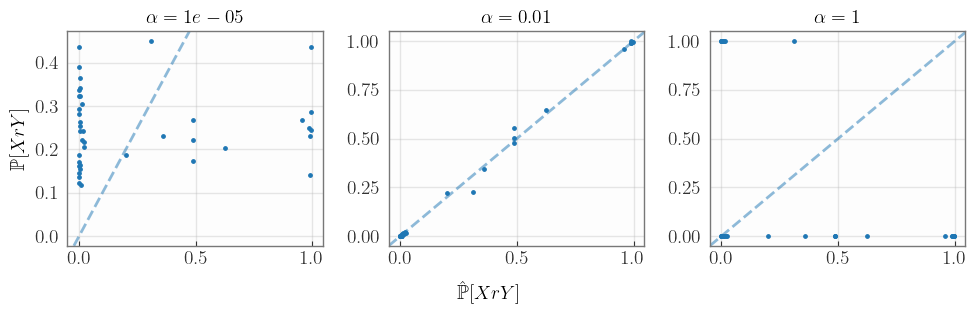

In [31]:
i = 1

fig = plt.figure(figsize=(10, 3))

for lr in marginals_per_dmid:
    ep = marginals_per_dmid[lr]

    plt.subplot(1, 3, i)
    plt.scatter(true_marginals, ep, s=6)
    plt.axline((0, 0), slope=1, linestyle="--", alpha=.5)
    plt.title(f"$\\alpha = {lr}$")

    if i == 1:
        plt.ylabel("$\\mathbb{P}[X r Y]$")

    i = i + 1

plt.tight_layout()
fig.supxlabel("$\\hat{\\mathbb{P}}[X r Y]$", fontsize=14, y=-5e-2)

plt.savefig("figures/learning_rates.pdf", bbox_inches="tight")


## Runtimes

In [9]:
reward_key = jax.random.key(reward_seed)
# Simulate the data (which is needed for certain reward functions)
data, dir_amat, bidir_amat, *_ = sample_linear_gaussian(
    reward_key, num_nodes, num_samples=1000
)
true_graph = from_amat((dir_amat + bidir_amat)[None])

seed = 42
key = jax.random.key(seed)

logr = create_log_reward(logr_t, data, true_graph)

In [10]:
state = create_state(bs, num_nodes)
# Create the GFlowNet
gfn = GFlowNet(num_nodes, dmid=64, seed=seed)


gfn, _, elapsed = train(gfn, state, key, logr, iterations, loss_t, return_elapsed=True)

true_marginals, estimated_marginals = eval_marginal(
    gfn, state, logr, graphs=all_graphs, key=key, num_rollouts=20
)

100%|██████████| 2000/2000 [00:31<00:00, 63.59it/s, loss=7.64e+00]


true None
estimated [[0.0000000e+00 4.3750000e-01 2.1093750e-02 5.4140627e-01]
 [9.9375004e-01 4.6875002e-03 0.0000000e+00 1.5625000e-03]
 [9.9609375e-01 0.0000000e+00 0.0000000e+00 3.9062500e-03]
 [9.4999999e-01 1.1718750e-02 1.2500000e-02 2.5781250e-02]
 [0.0000000e+00 9.9765629e-01 1.5625000e-03 7.8125001e-04]
 [0.0000000e+00 8.5937502e-03 5.9609377e-01 3.9531252e-01]
 [9.8906249e-01 1.5625000e-03 7.8125001e-04 8.5937502e-03]
 [9.8671877e-01 0.0000000e+00 1.0156251e-02 3.1250000e-03]
 [9.9296874e-01 1.5625000e-03 3.1250000e-03 2.3437501e-03]
 [0.0000000e+00 5.1484376e-01 2.4921875e-01 2.3593751e-01]]
